In [ ]:
pip install tensorflow numpy pandas matplotlib

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import imdb

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 500
train_data = pad_sequences(train_data, maxlen=max_length)
test_data = pad_sequences(test_data, maxlen=max_length)

In [ ]:
model = keras.Sequential([
    keras.layers.Embedding(10000, 16),
    keras.layers.GlobalAveragePooling1D(),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [ ]:
model.fit(train_data, train_labels, epochs=10, batch_size=512, validation_data=(test_data, test_labels))

Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.5160 - loss: 0.6927 - val_accuracy: 0.5613 - val_loss: 0.6898
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.5865 - loss: 0.6873 - val_accuracy: 0.6991 - val_loss: 0.6766
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.6652 - loss: 0.6690 - val_accuracy: 0.7265 - val_loss: 0.6442
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.7360 - loss: 0.6307 - val_accuracy: 0.7636 - val_loss: 0.5954
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.7544 - loss: 0.5786 - val_accuracy: 0.7899 - val_loss: 0.5401
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.7931 - loss: 0.5199 - val_accuracy: 0.8208 - val_loss: 0.4895
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.8293 - loss: 0.4662 - val_accuracy: 0.8146 - val_loss: 0.4516
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.8451 - loss: 0.4199 - val_accuracy: 0.8185 - v

In [ ]:
test_loss, test_acc = model.evaluate(test_data, test_labels)
print(f"Test Accuracy: {test_acc}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8565 - loss: 0.3727
Test Accuracy: 0.8561599850654602


Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.8724 - loss: 0.3448 - val_accuracy: 0.8640 - val_loss: 0.3595
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.8731 - loss: 0.3313 - val_accuracy: 0.8652 - val_loss: 0.3492
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8859 - loss: 0.3109 - val_accuracy: 0.8675 - val_loss: 0.3372
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.8792 - loss: 0.3092 - val_accuracy: 0.8734 - val_loss: 0.3276
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8920 - loss: 0.2860 - val_accuracy: 0.8739 - val_loss: 0.3222
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.8917 - loss: 0.2852 - val_accuracy: 0.8762 - val_loss: 0.3151
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9023 - loss: 0.2691 - val_accuracy: 0.8751 - val_loss: 0.3131
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9051 - loss: 0.2588 - val_accuracy: 0.8785 - v

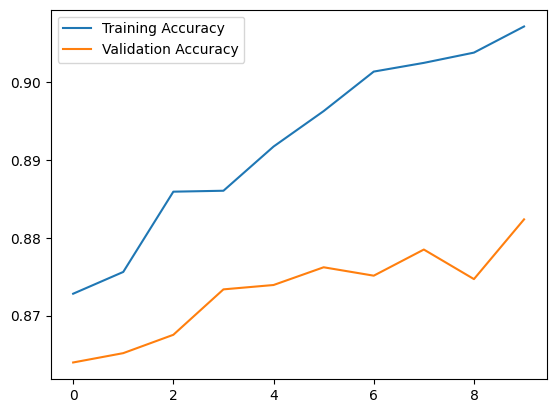

In [ ]:
import matplotlib.pyplot as plt

history = model.fit(train_data, train_labels, epochs=10, batch_size=512, validation_data=(test_data, test_labels))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
sample_review = ["This movie was absolutely amazing, the performances were stellar!"]
# You would need to preprocess this text into numerical format before testing it on the model.

In [ ]:
def predict_review(review):
    encoded_review = tokenizer.texts_to_sequences([review])
    padded_review = pad_sequences(encoded_review, maxlen=max_length)
    prediction = model.predict(padded_review)[0][0]
    sentiment = "Positive Review" if prediction > 0.5 else "Negative Review"
    print(sentiment)

In [ ]:
predict_review=("This movie was absolutely amazing! The acting was phenomenal.")  # Should return Positive Review
predict_review=("I regret watching this. The plot was weak and very predictable.")  # Should return Negative Review

In [ ]:
test_loss, test_acc = model.evaluate(test_data, test_labels)
print(f"Test Accuracy: {test_acc:.2%}")  # Outputs accuracy in percentage format

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8832 - loss: 0.2974
Test Accuracy: 88.24%


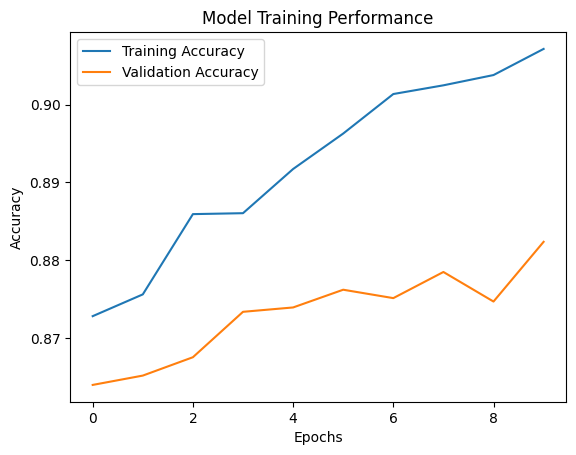

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Training Performance")
plt.show()

In [ ]:
import keras.saving
keras.saving.save_model(model, "my_model.keras")